Supermarket Sales Dataset:

  Branch       City  Gender            Product line      Payment Target
0      A     Yangon  Female       Health and beauty      Ewallet    Yes
1      C  Naypyitaw  Female  Electronic accessories         Cash     No
2      A     Yangon    Male      Home and lifestyle  Credit card     No
3      A     Yangon    Male       Health and beauty      Ewallet    Yes
4      A     Yangon    Male       Sports and travel      Ewallet     No
5      C  Naypyitaw    Male  Electronic accessories      Ewallet     No
6      A     Yangon  Female  Electronic accessories      Ewallet    Yes
7      C  Naypyitaw  Female      Home and lifestyle      Ewallet     No
8      A     Yangon  Female       Health and beauty  Credit card    Yes
9      B   Mandalay  Female      Food and beverages  Credit card    Yes

Positive Example:
['A', 'Yangon', 'Female', 'Health and beauty', 'Ewallet']
Hypothesis:
['A', 'Yangon', 'Female', 'Health and beauty', 'Ewallet']

Positive Example:
['A', 'Yangon'

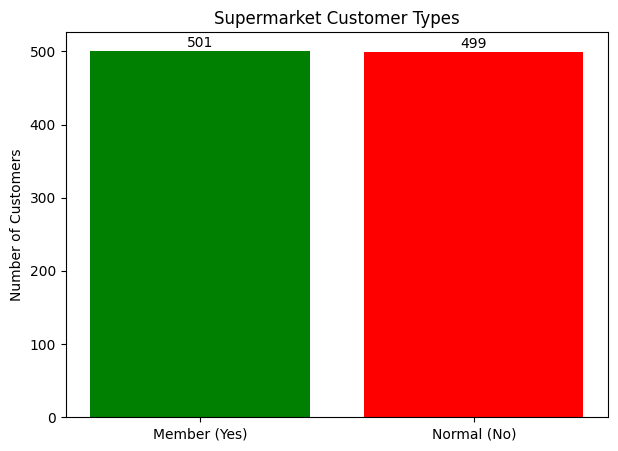

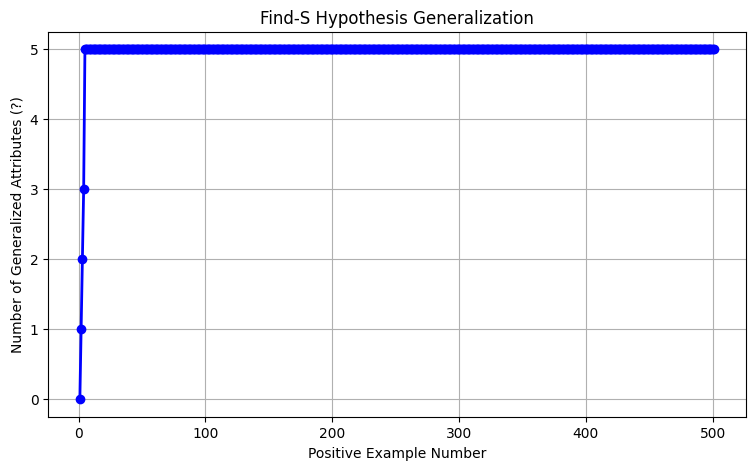

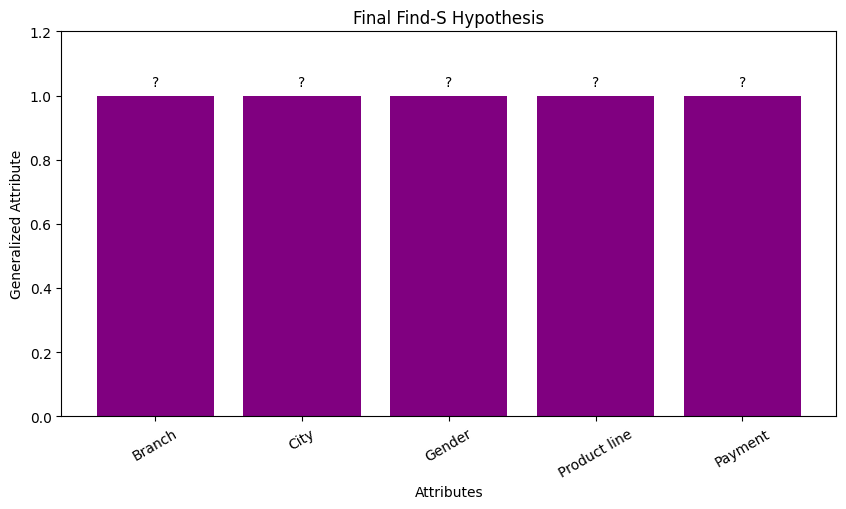

In [7]:
import pandas as pd
import matplotlib.pyplot as plt

DATA_URL = "https://raw.githubusercontent.com/selva86/datasets/master/supermarket_sales.csv"

data = pd.read_csv(DATA_URL)

data.columns = data.columns.str.strip()

data = data[
    [
        "Branch",
        "City",
        "Gender",
        "Product line",
        "Payment",
        "Customer type"
    ]
].copy()

data["Target"] = data["Customer type"].map({
    "Member": "Yes",
    "Normal": "No"
})

data = data.drop(columns=["Customer type"])

print("Supermarket Sales Dataset:\n")
print(data.head(10))

attributes = list(data.columns[:-1])
target = data.columns[-1]

hypothesis = ['0'] * len(attributes)

hypothesis_history = []

for _, row in data.iterrows():

    if row[target] == "Yes":

        for i, attribute in enumerate(attributes):

            if hypothesis[i] == '0':
                hypothesis[i] = row[attribute]

            elif hypothesis[i] != row[attribute]:
                hypothesis[i] = '?'

        hypothesis_history.append(hypothesis.copy())

        print("\nPositive Example:")
        print(list(row[attributes]))

        print("Hypothesis:")
        print(hypothesis)

print("\n" + "=" * 60)
print("FINAL FIND-S HYPOTHESIS")
print("=" * 60)

for attribute, value in zip(attributes, hypothesis):
    print(attribute, ":", value)

print("\nFinal Hypothesis:")
print(hypothesis)

positive_count = (data[target] == "Yes").sum()
negative_count = (data[target] == "No").sum()

plt.figure(figsize=(7, 5))

plt.bar(
    ["Member (Yes)", "Normal (No)"],
    [positive_count, negative_count],
    color=["green", "red"]
)

plt.title("Supermarket Customer Types")
plt.ylabel("Number of Customers")

for i, value in enumerate([positive_count, negative_count]):
    plt.text(i, value + 5, str(value), ha="center")

plt.show()

generalization = [
    h.count("?") for h in hypothesis_history
]

plt.figure(figsize=(9, 5))

plt.plot(
    range(1, len(generalization) + 1),
    generalization,
    marker="o",
    color="blue",
    linewidth=2
)

plt.title("Find-S Hypothesis Generalization")
plt.xlabel("Positive Example Number")
plt.ylabel("Number of Generalized Attributes (?)")
plt.grid(True)

plt.show()

plt.figure(figsize=(10, 5))

final_values = [
    1 if value == "?" else 0
    for value in hypothesis
]

plt.bar(
    attributes,
    final_values,
    color="purple"
)

plt.title("Final Find-S Hypothesis")
plt.xlabel("Attributes")
plt.ylabel("Generalized Attribute")

plt.ylim(0, 1.2)

for i, value in enumerate(final_values):

    label = "?" if value == 1 else hypothesis[i]

    plt.text(
        i,
        value + 0.03,
        label,
        ha="center"
    )

plt.xticks(rotation=30)

plt.show()
